# Task 4: Visual Inspection of Segmentation Quality

Dice scores (Task 2) summarise each organ in one number, so they hide *where* and *why* a model fails.
This notebook overlays the saved Swin UNETR predictions (`results/predictions/*_overlap0.5`) on the
native CT and ground truth of the 6 BTCV validation scans (`img0035`–`img0040`) and looks at:

1. a case with **good** segmentation performance,
2. a case with **relatively poor** performance,
3. **typical segmentation errors** and their likely causes.

All plots use the native voxel grid (the predictions were resampled back to it in Task 2). CT is shown with the
same HU window the model sees (−175 … 250 HU). Axial slices use the radiological convention (anterior at the top,
patient's right on the viewer's left). Error maps: **red = false positive**, **blue = false negative**,
**green = voxel assigned to the wrong organ**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import BTCV_ORGANS, FIGURES_DIR, METRICS_DIR, MODEL_CONFIGS
from src.visualization import (
    SHORT_NAMES, axial, component_stats, confusion_voxels, coronal, crop_box, dice,
    load_case, organ_legend_handles, pick_slice, plot_case_slice, plot_model_comparison, window_ct,
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CASES = ["0035", "0036", "0037", "0038", "0039", "0040"]
MODELS = ["base", "small", "tiny"]
ORGANS = list(BTCV_ORGANS.values())
plt.rcParams["figure.dpi"] = 90

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"task4_{name}.png", dpi=150, bbox_inches="tight")

## 1. Selecting cases from the quantitative results

The per-case/per-organ Dice tables from Task 2 tell us which cases to look at. First, a sanity check that the
loaded volumes line up: recomputing Dice from the NIfTI files must reproduce the CSV values.

In [2]:
dice_tables = {m: pd.read_csv(METRICS_DIR / f"btcv_dice_{m}_overlap0.5.csv") for m in MODELS}
for m, df in dice_tables.items():
    df["case_id"] = df["case"].str.extract(r"img(\d{4})")[0]
    df.set_index("case_id", inplace=True)

# Sanity check: recompute a few Dice values from the saved predictions
for case_id, organ_idx in [("0037", 7), ("0039", 6), ("0036", 11)]:
    _, gt, pred, _ = load_case(case_id, "base")
    d = dice(pred == organ_idx, gt == organ_idx)
    csv = dice_tables["base"].loc[case_id, BTCV_ORGANS[organ_idx]]
    print(f"img{case_id} {BTCV_ORGANS[organ_idx]:<10s} recomputed={d:.4f}  csv={csv:.4f}")
    assert abs(d - csv) < 1e-6

base = dice_tables["base"]
best_case, worst_case = base["mean_dice"].idxmax(), base["mean_dice"].idxmin()
print(f"\nBase model: best case img{best_case} ({base.loc[best_case, 'mean_dice']:.3f}), "
      f"worst case img{worst_case} ({base.loc[worst_case, 'mean_dice']:.3f})")

img0037 Stomach    recomputed=0.5560  csv=0.5560
img0039 Liver      recomputed=0.9485  csv=0.9485


img0036 Pancreas   recomputed=0.7966  csv=0.7966

Base model: best case img0039 (0.838), worst case img0035 (0.770)


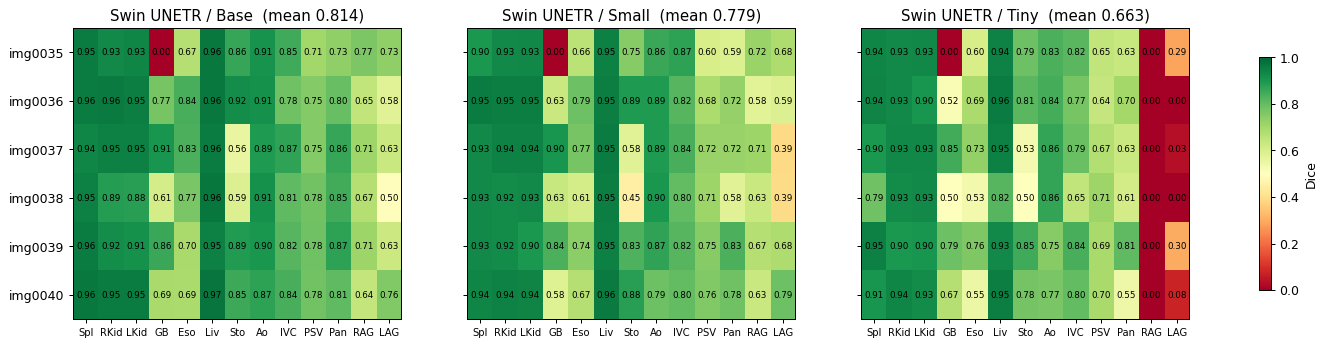

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.2), sharey=True)
for ax, m in zip(axes, MODELS):
    mat = dice_tables[m][ORGANS].values
    im = ax.imshow(mat, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(13), [SHORT_NAMES[k] for k in BTCV_ORGANS], fontsize=8)
    ax.set_yticks(range(len(CASES)), [f"img{c}" for c in CASES])
    ax.set_title(f"{MODEL_CONFIGS[m]['name']}  (mean {dice_tables[m]['mean_dice'].mean():.3f})")
fig.colorbar(im, ax=axes, shrink=0.8, label="Dice")
save(fig, "dice_heatmap")
plt.show()

**Observations from the table.**
- Large, high-contrast organs (liver, spleen, kidneys) reach Dice ≥ 0.9 for every model and case.
- The low values cluster in three places: **stomach** in `img0037`/`img0038`, the **gallbladder of `img0035` (0.00 for every model)**, and
  **small structures** (adrenals, esophagus, portal/splenic veins). The Tiny model scores **exactly 0 on the right adrenal gland in all six cases**.
- **Good case:** `img0039` (Base, mean Dice 0.838). **Poor case:** `img0035` (Base, 0.770).

## 2. Good case: `img0039`, Swin UNETR / Base (mean Dice 0.838)

Three axial levels (upper abdomen, pancreas/adrenals, kidneys) and one coronal section.

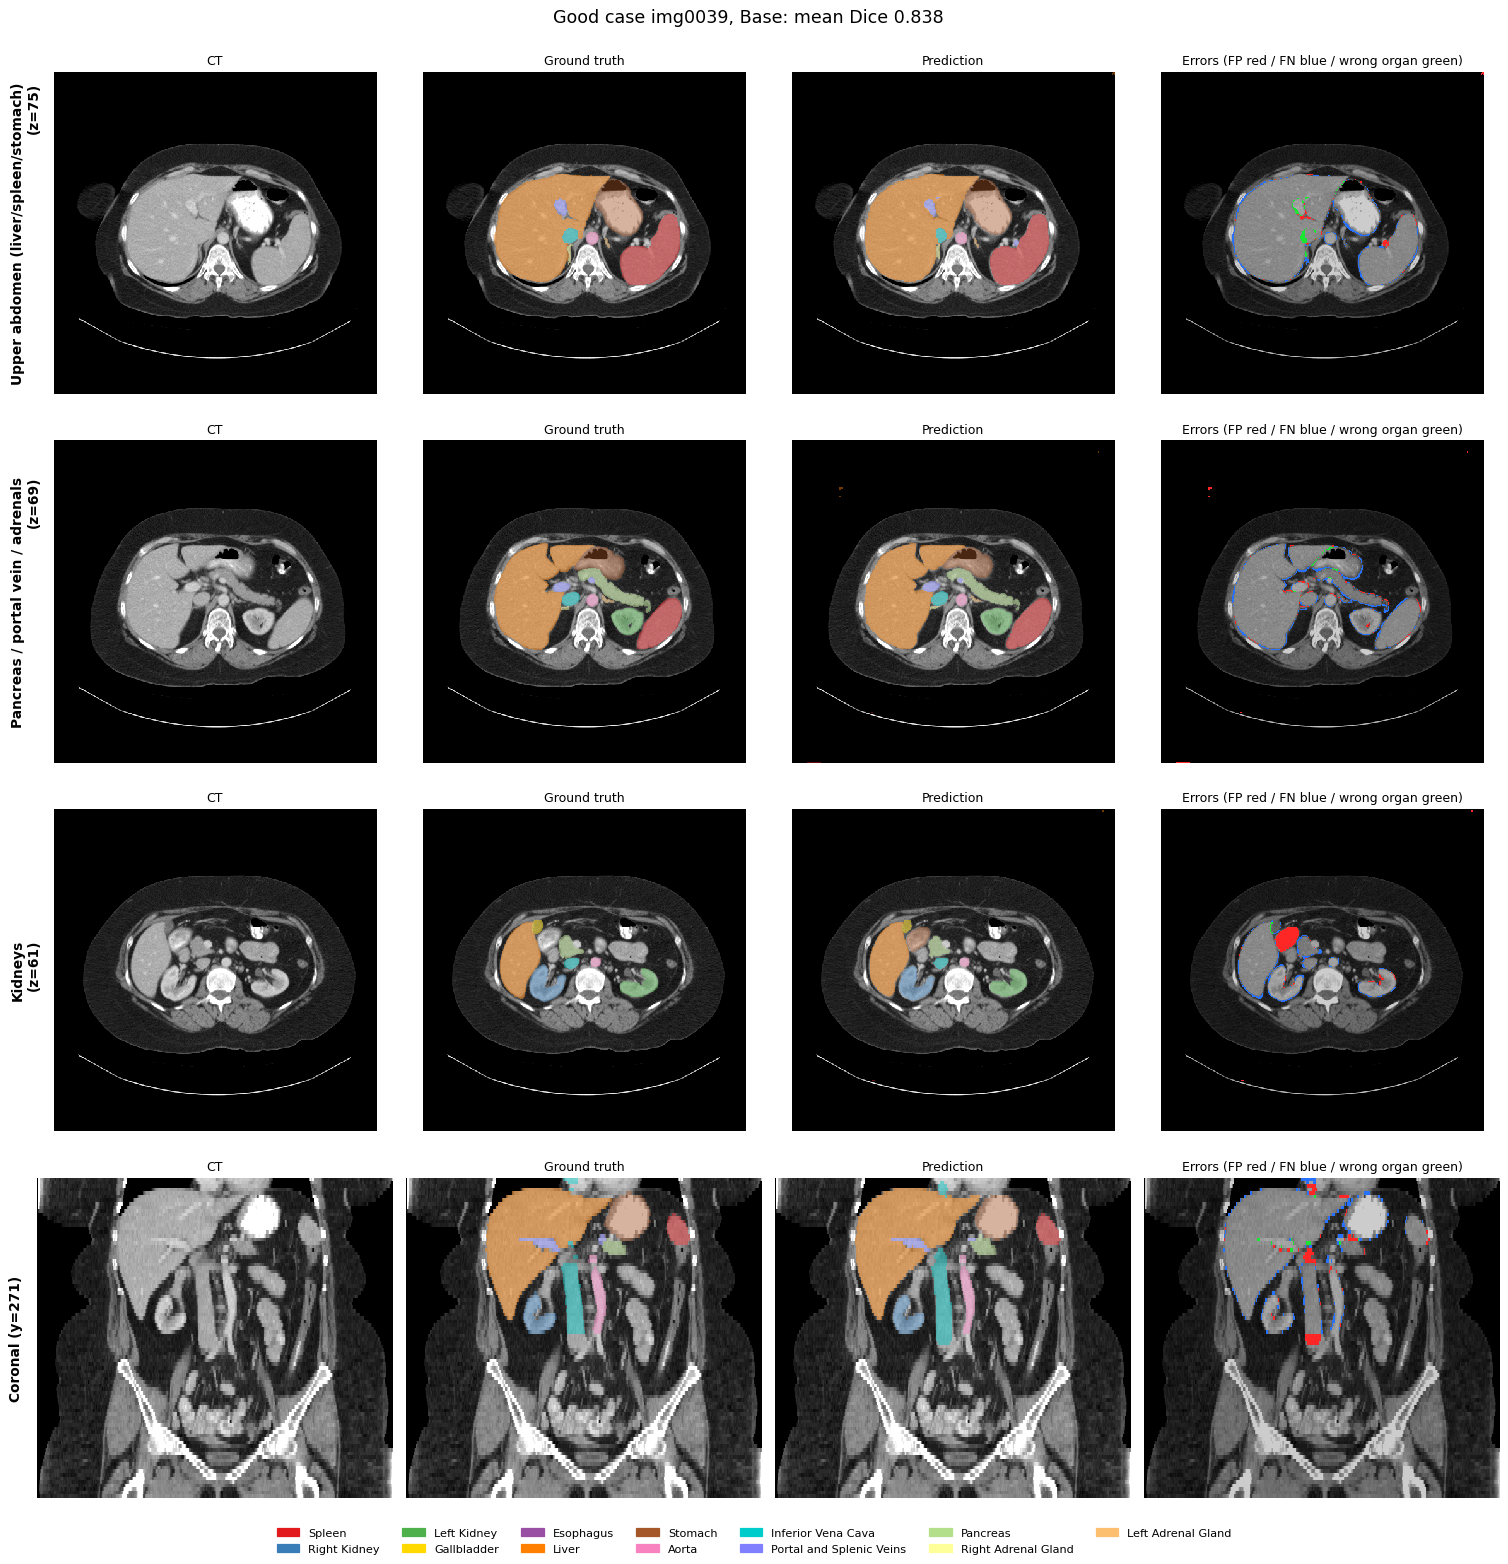

Spleen                      0.956
Right Kidney                0.921
Left Kidney                 0.913
Gallbladder                 0.858
Esophagus                   0.695
Liver                       0.948
Stomach                     0.889
Aorta                       0.900
Inferior Vena Cava          0.820
Portal and Splenic Veins    0.782
Pancreas                    0.873
Right Adrenal Gland         0.713
Left Adrenal Gland          0.628


In [4]:
ct, gt, pred, sp = load_case(best_case, "base")
levels = {
    "Upper abdomen (liver/spleen/stomach)": pick_slice(gt, pred, organ=1),
    "Pancreas / portal vein / adrenals":    pick_slice(gt, pred, organ=11),
    "Kidneys":                              pick_slice(gt, pred, organ=2),
}
fig, axes = plt.subplots(len(levels) + 1, 4, figsize=(17, 4.4 * (len(levels) + 1)))
for row, (name, z) in zip(axes, levels.items()):
    plot_case_slice(ct, gt, pred, z, axes=row, row_label=f"{name}\n(z={z})")
y = pick_slice(gt, pred, organ=8, axis=1)  # coronal slice through the aorta
plot_case_slice(ct, gt, pred, y, view="coronal", axes=axes[-1], aspect=sp[2] / sp[0],
                row_label=f"Coronal (y={y})")
fig.legend(handles=organ_legend_handles(), loc="lower center", ncol=7, fontsize=9, frameon=False)
fig.suptitle(f"Good case img{best_case}, Base: mean Dice {base.loc[best_case, 'mean_dice']:.3f}", fontsize=14)
fig.tight_layout(rect=(0, 0.03, 1, 0.98))
save(fig, "good_case")
plt.show()
print(base.loc[best_case, ORGANS].astype(float).round(3).to_string())

**What good looks like.** Organ topology, position and extent match the reference almost perfectly. Most
remaining errors are **1–2 voxel rims along organ boundaries** (thin red/blue outlines). The only larger error visible
is at the kidney level (row 3): a contrast-filled **duodenal loop is labelled as stomach** (red blob). The two are
continuous, look alike, and the boundary between them (the pylorus) cannot be seen on a single slice. These come from where
exactly the boundary is drawn, and from resampling the prediction between the 1.5×1.5×2 mm model grid and the
native 0.98×0.98×5 mm grid with nearest-neighbour interpolation. In the coronal view the 5 mm slice spacing gives
a visible staircase at the superior and inferior organ poles, where both label and prediction are coarse. The weakest organ
in this case is again the left adrenal gland (0.63). The structure is only a few voxels thick, so a one-voxel boundary shift
already costs a large fraction of its Dice.

## 3. Poor case: `img0035`, Swin UNETR / Base (mean Dice 0.770)

`img0035` ranks lowest for Base and Small, almost entirely because of the **gallbladder Dice of 0.00**. The reason is in the label:

In [5]:
ct, gt, pred, sp = load_case(worst_case, "base")
vox_ml = np.prod(sp) / 1000
for m in MODELS:
    p = load_case(worst_case, m)[2]
    print(f"{m:<5s}: GT gallbladder = {(gt == 4).sum():5d} voxels | predicted gallbladder = "
          f"{(p == 4).sum():5d} voxels ({(p == 4).sum() * vox_ml:.1f} ml)")
gb = pred == 4
print(f"\nHU inside predicted 'gallbladder': median {np.median(ct[gb]):.0f} "
      f"(IQR {np.percentile(ct[gb], 25):.0f} to {np.percentile(ct[gb], 75):.0f}); liver median {np.median(ct[gt == 6]):.0f}")

base : GT gallbladder =     0 voxels | predicted gallbladder =  5446 voxels (23.0 ml)
small: GT gallbladder =     0 voxels | predicted gallbladder =  4985 voxels (21.1 ml)


tiny : GT gallbladder =     0 voxels | predicted gallbladder =  4636 voxels (19.6 ml)

HU inside predicted 'gallbladder': median 27 (IQR 11 to 51); liver median 109


Label `0035` contains **no gallbladder at all**. The organ is absent or was not annotated, e.g. after a cholecystectomy.
Every model still predicts a ~20 ml "gallbladder" in the gallbladder fossa. Because of how Dice is defined
in the official evaluation (`dice()` returns 0 if the reference is empty), this one false positive becomes a 0 that is
averaged into the case mean as if the whole organ had been missed. **Without the gallbladder, Base on `img0035`
would average 0.834**, which is as good as the best case. The figure shows what the model labelled as gallbladder:

Base img0035 mean Dice without gallbladder: 0.834


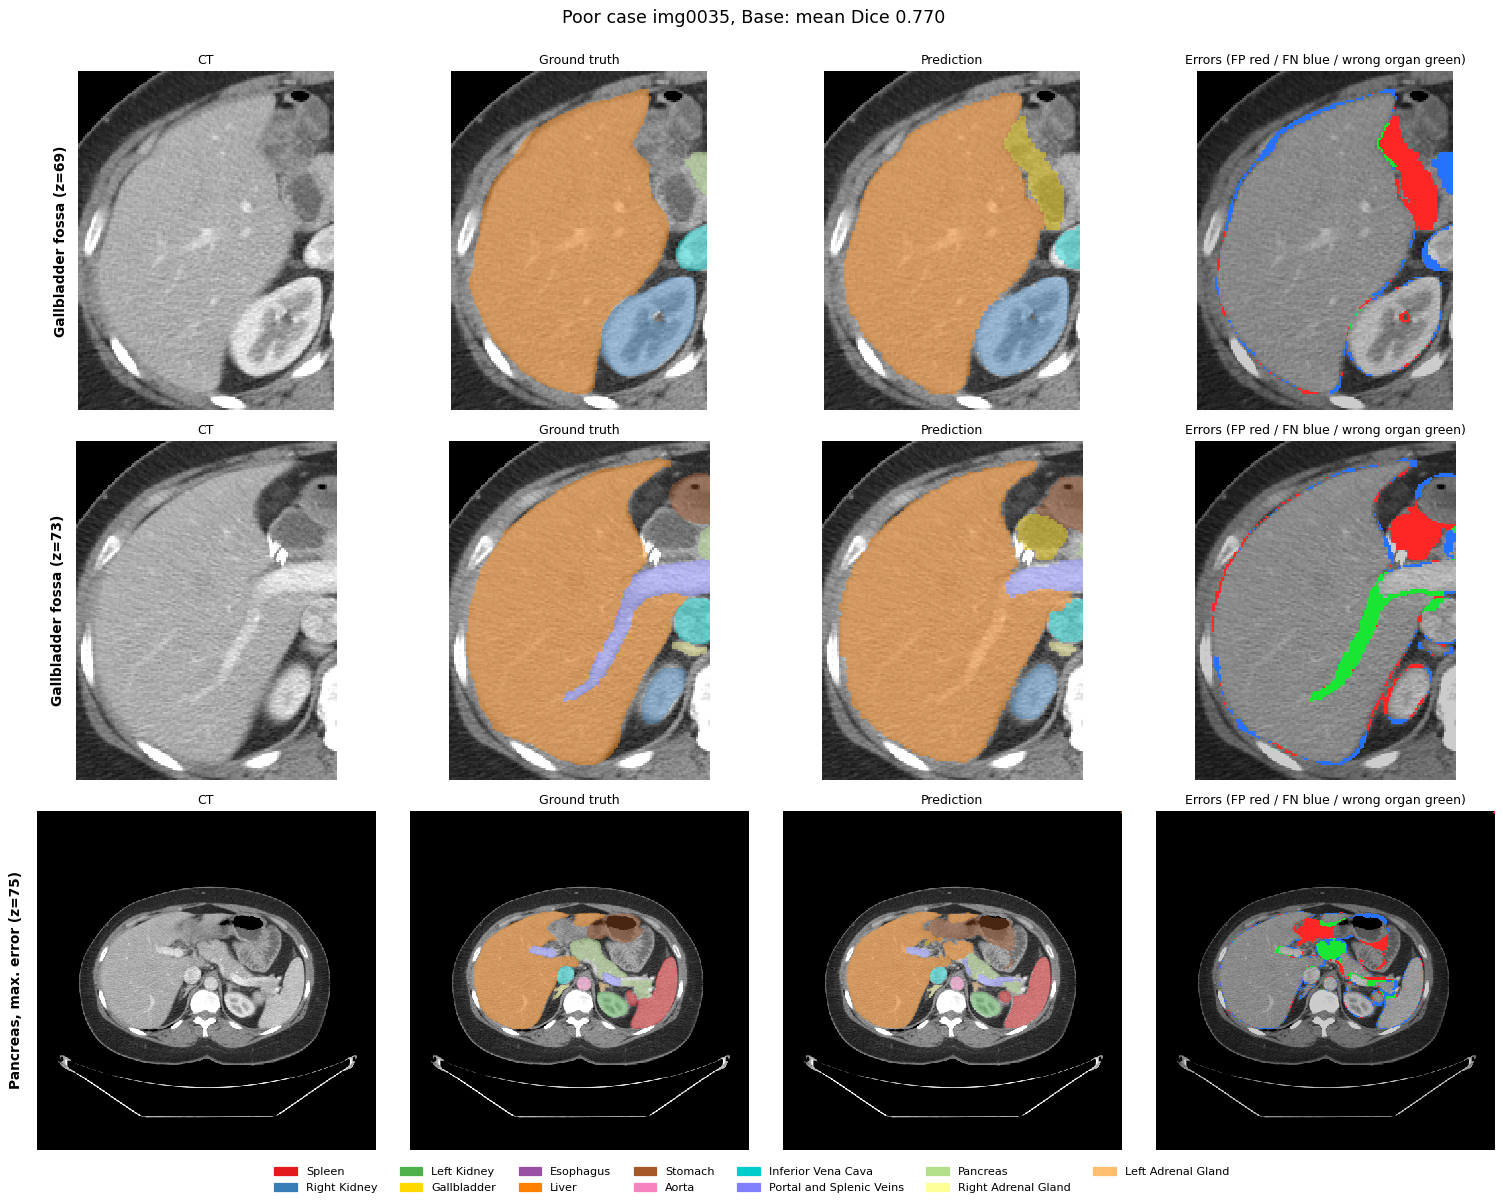

Spleen                      0.953
Right Kidney                0.929
Left Kidney                 0.934
Gallbladder                 0.000
Esophagus                   0.672
Liver                       0.962
Stomach                     0.861
Aorta                       0.910
Inferior Vena Cava          0.851
Portal and Splenic Veins    0.707
Pancreas                    0.733
Right Adrenal Gland         0.765
Left Adrenal Gland          0.733


In [6]:
print(f"Base img{worst_case} mean Dice without gallbladder: {base.loc[worst_case, [o for o in ORGANS if o != 'Gallbladder']].astype(float).mean():.3f}")

z_gb = pick_slice(gt, pred, organ=4, mode="max_pred")
z_low = pick_slice(gt, pred, organ=11, mode="max_error")  # slice with most pancreas errors
fig, axes = plt.subplots(3, 4, figsize=(17, 13.5))
for row, z in zip(axes[:2], (z_gb - 2, z_gb + 2)):
    box = crop_box(axial(pred, z) == 4, axial(gt, z) == 6, margin=10)
    box = (box[0], box[1], box[2], min(box[3], box[2] + 260))
    plot_case_slice(ct, gt, pred, z, crop=box, axes=row, row_label=f"Gallbladder fossa (z={z})")
plot_case_slice(ct, gt, pred, z_low, axes=axes[2], row_label=f"Pancreas, max. error (z={z_low})")
fig.legend(handles=organ_legend_handles(), loc="lower center", ncol=7, fontsize=9, frameon=False)
fig.suptitle(f"Poor case img{worst_case}, Base: mean Dice {base.loc[worst_case, 'mean_dice']:.3f}", fontsize=14)
fig.tight_layout(rect=(0, 0.03, 1, 0.98))
save(fig, "poor_case")
plt.show()
print(base.loc[worst_case, ORGANS].astype(float).round(3).to_string())

**Interpretation.**
- **False-positive gallbladder (rows 1–2, red).** The model places a gallbladder on a **hypodense (~25 HU), fluid-like
  structure along the medial liver edge, next to the gastric antrum**. This is most likely the fluid-filled duodenal bulb or
  proximal duodenum, possibly a gallbladder remnant the annotator did not label.
  The training labels *always* contain a gallbladder in this position, so the network has learned a strong anatomical prior
  ("there is a fluid-density sac under the liver") and cannot handle **atypical anatomy**. The image looks plausible, so the model has no
  way to know the organ is absent.
- **Annotation-convention errors (row 2, green).** The **intrahepatic portal vein branch** is labelled as *portal vein* in
  the reference but predicted as *liver*. These voxels are anatomically correct for both labels; the error comes from the
  annotation protocol, which follows the vessel into the liver in some scans but not in others.
- The remaining real weaknesses of this case are the **esophagus (0.67)**, **portal/splenic veins (0.71)**, the **pancreas (0.73)** and
  the **adrenals (0.73–0.77)**: all small or thin, low-contrast structures. Row 3 shows that pancreas errors sit at its boundary
  with the duodenum and the splenic vein.

## 4. Typical segmentation errors

### 4a. Gas-filled stomach: large false negatives (`img0038`, `img0037`)

Stomach Dice for Base drops to **0.59 (`img0038`)** and **0.56 (`img0037`)**, compared with 0.85–0.92 in the other cases.

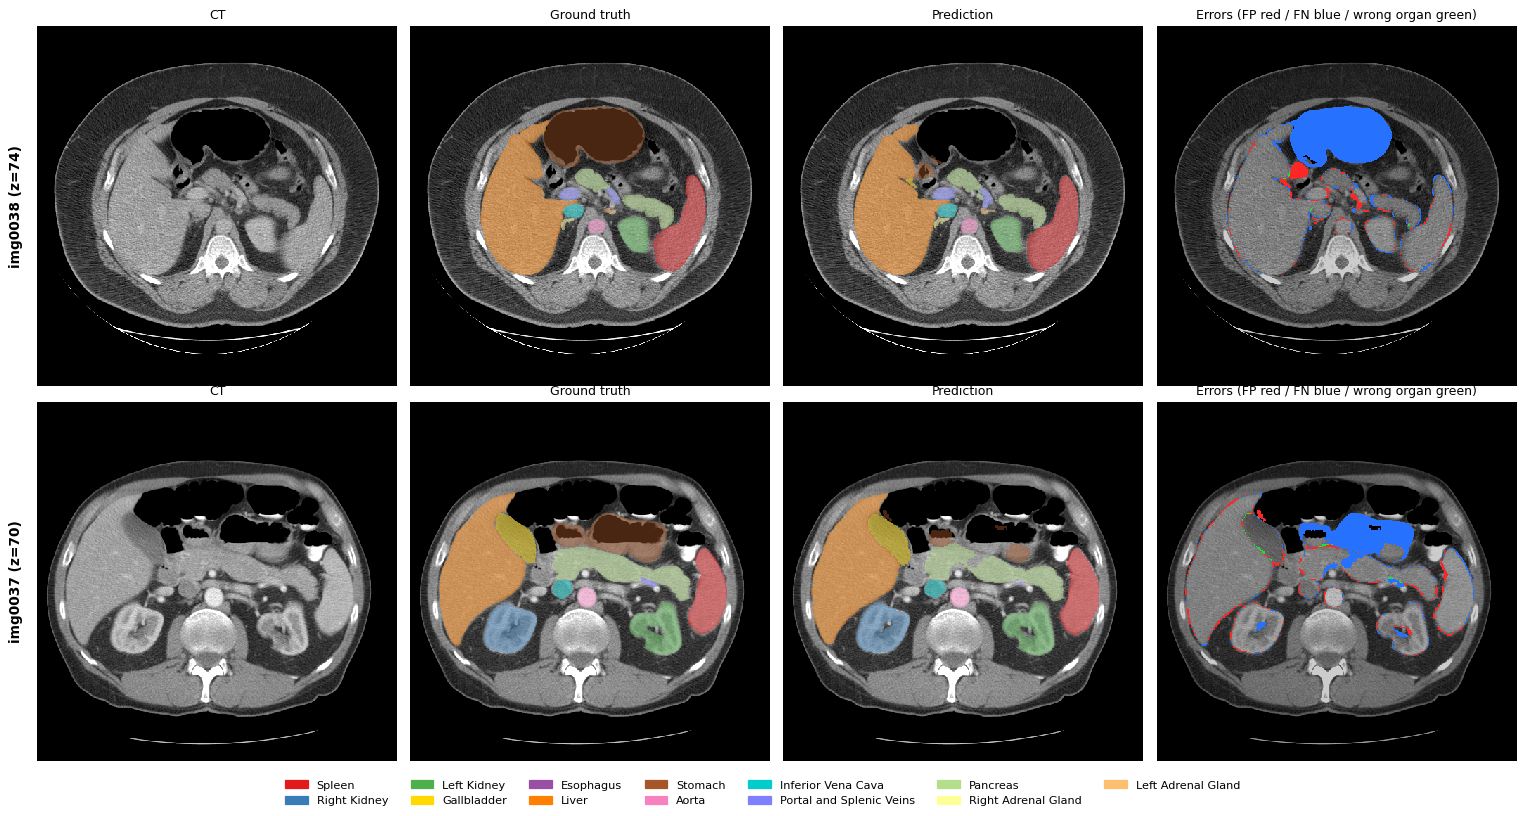

,stomach Dice,recall,missed vox → background,missed vox with HU < −175 (gas)
case,,,,
img0035,0.86,0.86,0.14,0.06
img0036,0.92,0.90,0.10,0.02
img0037,0.56,0.40,0.50,0.47
img0038,0.59,0.43,0.56,0.79
img0039,0.89,0.90,0.09,0.00
img0040,0.85,0.77,0.22,0.17


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
stomach_stats = []
for row, case_id in zip(axes, ("0038", "0037")):
    ct, gt, pred, _ = load_case(case_id, "base")
    z = pick_slice(gt, pred, organ=7, mode="max_error")
    plot_case_slice(ct, gt, pred, z, axes=row, row_label=f"img{case_id} (z={z})")
fig.legend(handles=organ_legend_handles(), loc="lower center", ncol=7, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "error_stomach_gas")
plt.show()

rows, hu = [], {}
for case_id in CASES:
    ct, gt, pred, _ = load_case(case_id, "base")
    g = gt == 7
    tp, fn = g & (pred == 7), g & (pred == 0)
    hu[case_id] = (ct[tp], ct[fn])
    rows.append({"case": f"img{case_id}", "stomach Dice": dice(pred == 7, g), "recall": tp.sum() / g.sum(),
                 "missed vox → background": fn.sum() / g.sum(),
                 "missed vox with HU < −175 (gas)": (ct[fn] < -175).mean()})
pd.DataFrame(rows).set_index("case").round(2)

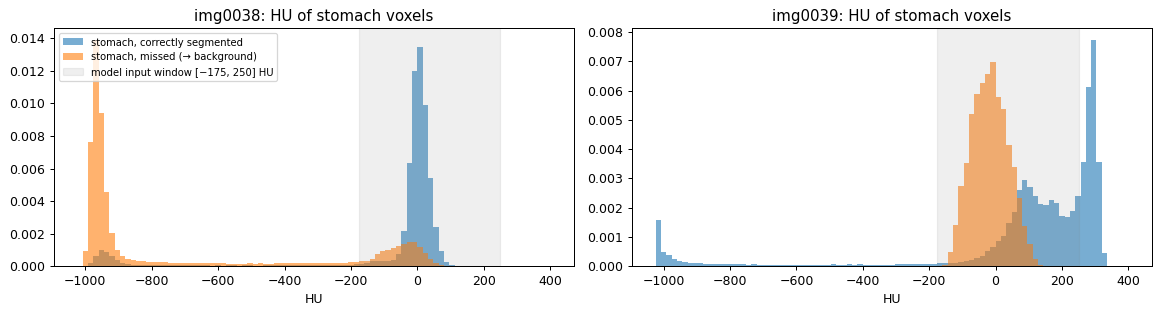

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=False)
for ax, case_id in zip(axes, ("0038", "0039")):
    tp_hu, fn_hu = hu[case_id]
    bins = np.linspace(-1024, 400, 90)
    ax.hist(tp_hu, bins, alpha=0.6, density=True, label="stomach, correctly segmented")
    ax.hist(fn_hu, bins, alpha=0.6, density=True, label="stomach, missed (→ background)")
    ax.axvspan(-175, 250, color="grey", alpha=0.12, label="model input window [−175, 250] HU")
    ax.set_title(f"img{case_id}: HU of stomach voxels")
    ax.set_xlabel("HU")
axes[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "error_stomach_hu")
plt.show()

**Failure mode:** the model segments the gastric **wall and fluid contents** but leaves the **gas-filled lumen** as background.
In `img0038` the missed voxels have a median of about −950 HU (pure air). In `img0037` about half of them are gas, and the rest are
the thin wall and fluid level next to the gas. The reference annotators labelled the whole stomach *including its lumen*.

**Likely explanation:**
1. **Intensity clipping.** Preprocessing clips CT to [−175, 250] HU, so gas (−1000 HU), fat (−100 HU) and the air outside the body
   all map to the same intensity 0. Inside the window the lumen looks exactly like background, and only context separates it.
2. **Training-data variability.** How full the stomach is (empty, food, fluid, gas, oral contrast) differs a lot between patients.
   With 24 training scans, very distended, gas-filled stomachs are rare, so the shape prior learned from the 96³ patches does not cover them.
3. **Patch context.** A distended stomach (≈ 20 × 15 cm) is larger than a 96³ patch at 1.5 mm (14.4 cm), so no
   single window sees the whole wall around the gas bubble.

### 4b. Small structures and model capacity (adrenal glands, esophagus)

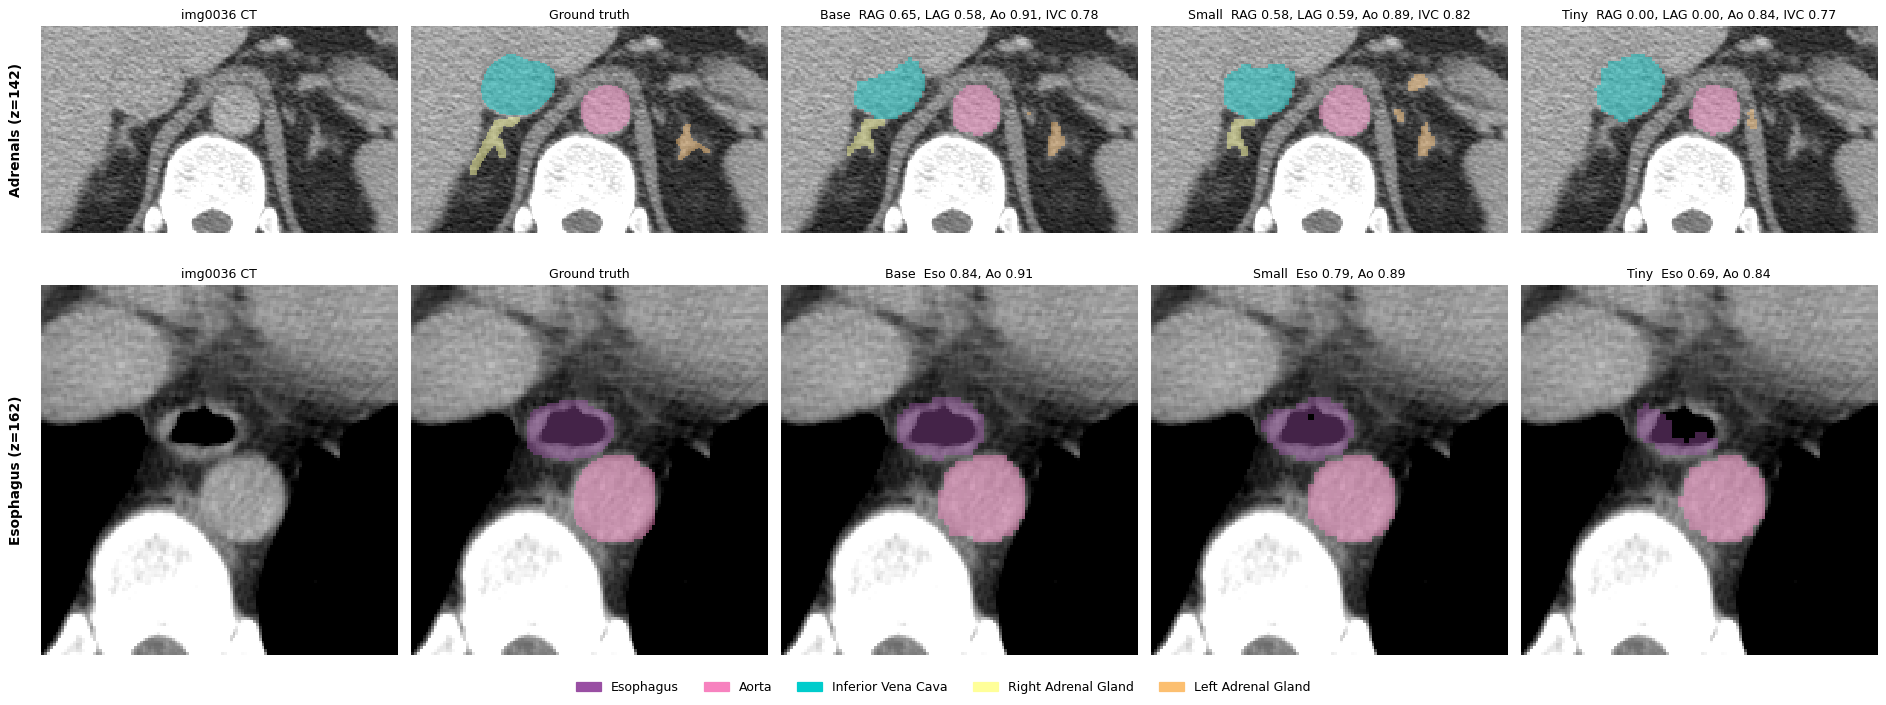

RAG GT / pred [ml]                       LAG GT / pred [ml]             \
model               base      small       tiny               base      small   
case                                                                           
0035           4.3 / 3.1  4.3 / 2.8  4.3 / 0.0          4.6 / 4.5  4.6 / 5.0   
0036           3.9 / 2.9  3.9 / 2.7  3.9 / 0.0          5.0 / 5.1  5.0 / 5.4   
0037           4.8 / 4.8  4.8 / 4.7  4.8 / 0.0          3.8 / 3.1  3.8 / 3.5   
0038           7.4 / 7.0  7.4 / 6.4  7.4 / 0.0          9.7 / 4.6  9.7 / 3.6   
0039           4.6 / 4.3  4.6 / 4.3  4.6 / 0.0          4.6 / 3.5  4.6 / 4.5   
0040           2.0 / 1.8  2.0 / 1.4  2.0 / 0.0          5.6 / 3.8  5.6 / 4.4   

                 Eso GT / pred [ml]                            
model       tiny               base        small         tiny  
case                                                           
0035   4.6 / 1.9        18.9 / 12.1  18.9 / 13.6  18.9 / 11.0  
0036   5.0 / 0.9        19.9 / 20.5  19.9 / 18.0  19.9 / 13.1  
0037   3.8 / 2.0        30.3 / 25.3  30.3 / 30.8  30.3 / 21.1  
0038   9.7 / 1.5        30.1 / 21.0  30.1 / 16.9  30.1 / 17.6  
0039   4.6 / 3.5         13.6 / 8.1   13.6 / 8.9   13.6 / 9.7  
0040   5.6 / 0.6        25.6 / 17.2  25.6 / 18.8  25.6 / 15.6

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(21, 8.6))
case_id = "0036"
ct, gt, _, sp = load_case(case_id, "base")
z = pick_slice(gt, gt, organ=12)
box = crop_box(axial(gt, z) == 12, axial(gt, z) == 13, axial(gt, z) == 8, margin=35)
plot_model_comparison(case_id, z, organs=[12, 13, 8, 9], crop=box, axes=axes[0])
axes[0, 0].text(-0.05, 0.5, f"Adrenals (z={z})", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
z = pick_slice(gt, gt, organ=5)
box = crop_box(axial(gt, z) == 5, axial(gt, z) == 8, margin=40)
plot_model_comparison(case_id, z, organs=[5, 8], crop=box, axes=axes[1])
axes[1, 0].text(-0.05, 0.5, f"Esophagus (z={z})", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
fig.legend(handles=organ_legend_handles([5, 8, 9, 12, 13]), loc="lower center", ncol=5, fontsize=10, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "error_small_structures")
plt.show()

vol = []
for m in MODELS:
    for case_id in CASES:
        _, gt, p, sp = load_case(case_id, m)
        vol.append({"model": m, "case": case_id,
                    **{f"{SHORT_NAMES[k]} GT / pred [ml]": f"{(gt == k).sum() * np.prod(sp) / 1e3:.1f} / {(p == k).sum() * np.prod(sp) / 1e3:.1f}" for k in (12, 13, 5)}})
pd.DataFrame(vol).pivot(index="case", columns="model")

**Failure mode:** the adrenal glands (≈ 2–4 ml each, a few millimetres thick) and the esophagus (a thin tube with little contrast
to the surrounding fat and diaphragmatic crura) have the lowest Dice of all organs for every model.
- Base and Small find the adrenals, but outline them only roughly (Base Dice 0.50–0.77). They follow the main body of the gland and
  miss its thin limbs. Small additionally produces detached islands around the left adrenal.
- The **esophagus** row shows the same gas problem as the stomach: the reference includes the air-filled lumen, which Base fills in,
  but Tiny leaves a hole in it.
- **Tiny never predicts a single right-adrenal voxel** in any of the six cases, and predicts the left adrenal only in fragments.
  This is **class collapse**. With `feature_size=12`, Tiny lacks the capacity to represent a class that makes up ~0.01 % of the voxels,
  so cross-entropy+Dice training is minimised by giving up on it.
- Dice is a poor metric for such small objects. A one-voxel shift of the boundary (0.7–1 mm in-plane, 3–5 mm through-plane) changes
  Dice by tens of percent. Nearest-neighbour resampling of the prediction from the 1.5×1.5×2 mm model grid back to the native grid
  adds up to half a model-voxel of displacement.

### 4c. Confusion between neighbouring structures

A voxel confusion matrix pooled over all six cases (Base) shows *where* misclassified voxels end up. Values are row-normalised
(fraction of each reference organ). The diagonal is masked so the errors are visible.

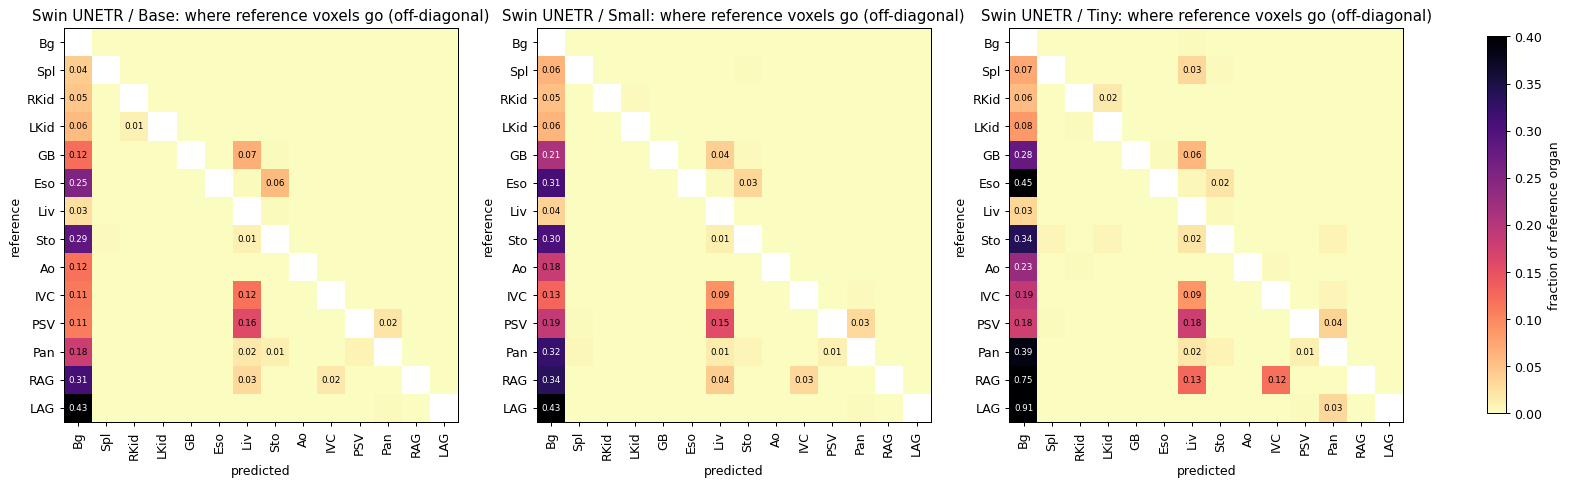

Largest organ↔organ confusions (Base, voxels):
   IVC → Liv    26765  (11.8% of IVC)
   PSV → Liv    12445  (15.9% of PSV)
   Sto → Liv    12261  (1.0% of Sto)
   Liv → Sto    10164  (0.2% of Liv)
  LKid → RKid    4599  (1.1% of LKid)
   Sto → Spl     4295  (0.4% of Sto)


In [10]:
conf = {m: sum(confusion_voxels(*load_case(c, m)[1:3]) for c in CASES) for m in MODELS}
names = ["Bg"] + [SHORT_NAMES[k] for k in BTCV_ORGANS]
fig, axes = plt.subplots(1, 3, figsize=(24, 6.8))
for ax, m in zip(axes, conf):
    C = conf[m].astype(float)
    R = C / C.sum(1, keepdims=True)
    np.fill_diagonal(R, np.nan)
    im = ax.imshow(R, cmap="magma_r", vmin=0, vmax=0.4)
    for i in range(14):
        for j in range(14):
            if i != j and R[i, j] >= 0.01:
                ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if R[i, j] > 0.2 else "black")
    ax.set_xticks(range(14), names, rotation=90)
    ax.set_yticks(range(14), names)
    ax.set_xlabel("predicted")
    ax.set_ylabel("reference")
    ax.set_title(f"{MODEL_CONFIGS[m]['name']}: where reference voxels go (off-diagonal)")
fig.colorbar(im, ax=axes, shrink=0.8, label="fraction of reference organ")
save(fig, "confusion_matrix")
plt.show()

C = conf["base"]
pairs = [(C[i, j], names[i], names[j]) for i in range(1, 14) for j in range(1, 14) if i != j]
print("Largest organ↔organ confusions (Base, voxels):")
for v, a, b in sorted(pairs, reverse=True)[:6]:
    print(f"  {a:>4s} → {b:<4s} {v:7d}  ({v / C[names.index(a)].sum():.1%} of {a})")

**Observations.**
- Most errors are **organ ↔ background**, i.e. under- or over-segmentation at boundaries. Organs are rarely confused *with each other*.
- The main organ-to-organ confusions are anatomically adjacent pairs with similar enhancement:
  - **IVC → liver (12 % of IVC voxels).** The retrohepatic IVC is embedded in the liver, and its labelled length differs between annotators.
  - **Portal/splenic vein → liver (16 %).** These are intrahepatic branches; see the poor case.
  - **Stomach ↔ liver/spleen.** The boundary is thin where the stomach touches these organs.
- One **laterality error**: in `img0038` about 4.6k voxels of the lower pole of the *left* kidney are labelled *right* kidney.
  A 96³ window that sees only one kidney has no global left/right context, so it must infer the side from local anatomy.
- Small and Tiny show the same pattern, getting stronger as model capacity shrinks. The *RAG* and *LAG* rows go almost entirely to background.

### 4d. Fragmented predictions / spurious islands

In [11]:
rows = []
for m in MODELS:
    for k, name in BTCV_ORGANS.items():
        n_pred, frac_out, n_gt = 0, [], 0
        for case_id in CASES:
            _, gt, p, _ = load_case(case_id, m)
            n, f = component_stats(p == k)
            n_pred += n; frac_out.append(f); n_gt += component_stats(gt == k)[0]
        rows.append({"model": m, "organ": SHORT_NAMES[k], "components (pred)": n_pred, "components (GT)": n_gt,
                     "% voxels outside largest comp.": 100 * np.mean(frac_out)})
cc = pd.DataFrame(rows)
cc.pivot(index="organ", columns="model", values=["components (pred)", "components (GT)", "% voxels outside largest comp."]).round(1)

components (pred)               components (GT)             \
model              base  small   tiny            base small tiny   
organ                                                              
Ao                 25.0   26.0   65.0             8.0   8.0  8.0   
Eso                16.0   25.0   21.0             6.0   6.0  6.0   
GB                 11.0   15.0   24.0             5.0   5.0  5.0   
IVC                20.0   20.0   66.0             6.0   6.0  6.0   
LAG                11.0   24.0   91.0             6.0   6.0  6.0   
LKid               25.0   81.0   48.0             6.0   6.0  6.0   
Liv               307.0  483.0  493.0             6.0   6.0  6.0   
PSV                24.0   32.0   48.0             6.0   6.0  6.0   
Pan                21.0   24.0   77.0             6.0   6.0  6.0   
RAG                11.0   18.0    0.0             6.0   6.0  6.0   
RKid               39.0   80.0   79.0             6.0   6.0  6.0   
Spl                99.0  266.0   97.0             6.0   6.0  6.0   
Sto                86.0  256.0  177.0             6.0   6.0  6.0   

      % voxels outside largest comp.              
model                           base small  tiny  
organ                                             
Ao                               2.6  10.3  12.8  
Eso                              5.0   7.6   5.8  
GB                               0.3   3.9   8.8  
IVC                              1.0   0.5   4.9  
LAG                              3.6   4.2  57.8  
LKid                             0.7   1.3   2.3  
Liv                              1.3   2.2   6.2  
PSV                              1.5  10.2   8.0  
Pan                              8.5   8.0  15.1  
RAG                              0.3   1.6   0.0  
RKid                             2.0   1.3   2.1  
Spl                              1.6   4.4   4.3  
Sto                              1.7   7.9   8.7

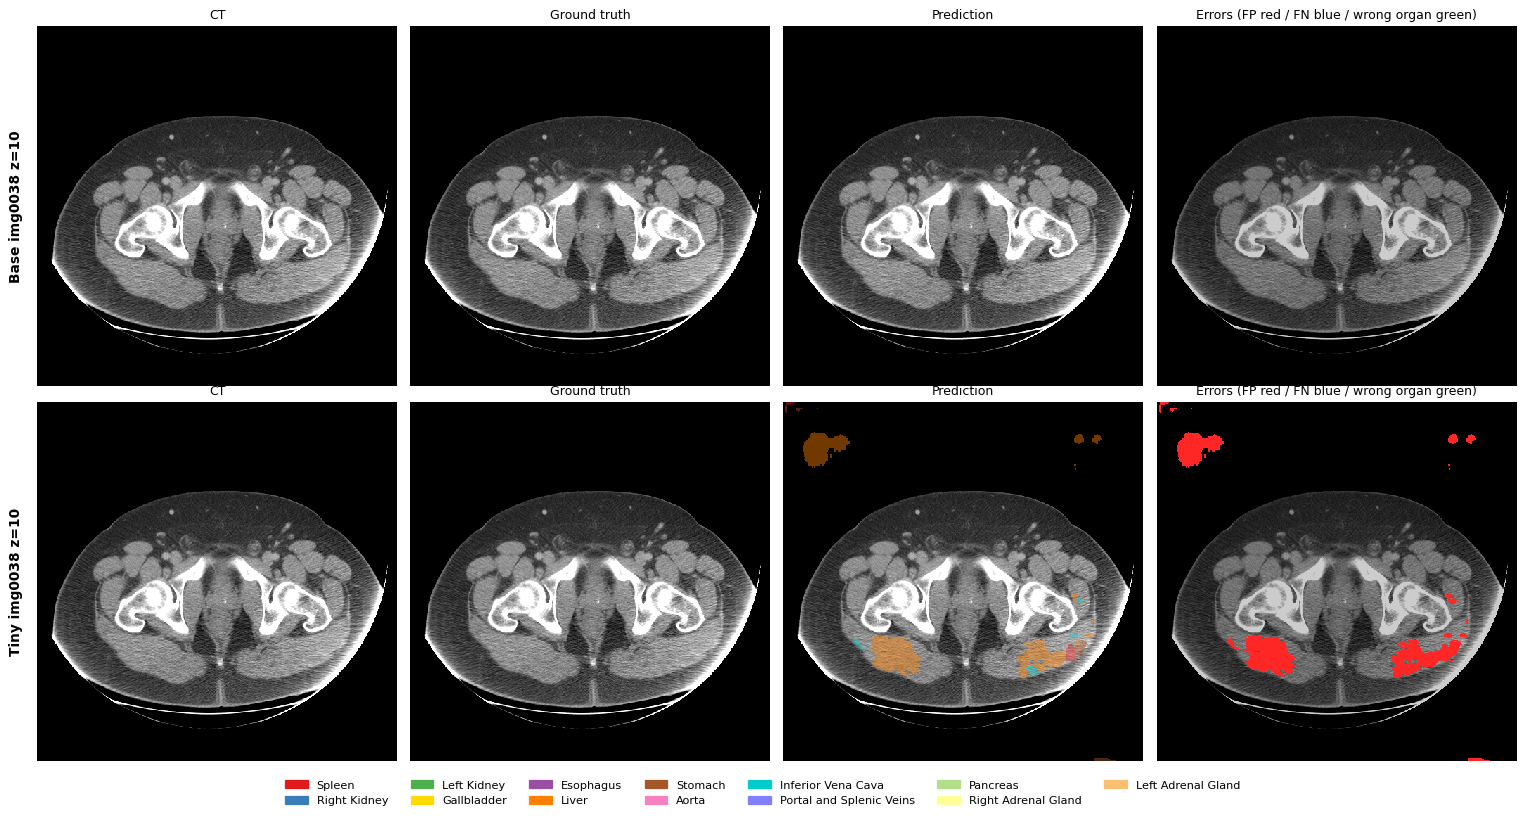

In [12]:
case_id = "0038"
ct, gt, p_tiny, sp = load_case(case_id, "tiny")
p_base = load_case(case_id, "base")[2]
fp_tiny = (p_tiny > 0) & (gt == 0)
z = int(np.argmax(fp_tiny.sum((0, 1))))
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
plot_case_slice(ct, gt, p_base, z, axes=axes[0], row_label=f"Base img{case_id} z={z}")
plot_case_slice(ct, gt, p_tiny, z, axes=axes[1], row_label=f"Tiny img{case_id} z={z}")
fig.legend(handles=organ_legend_handles(), loc="lower center", ncol=7, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "error_fragments")
plt.show()

**Failure mode:** the predictions contain many small **disconnected islands**. The reference has one component per organ (two for the aorta
in a few cases). Even Base produces 11–99 islands per organ, and ~300 for the liver, summed over 6 cases. Small and Tiny produce 2–4× more
(e.g. Small: 256 stomach and 266 spleen components). For most organs the islands hold only 1–10 % of the voxels, but **58 % of Tiny's
left-adrenal prediction lies outside its largest component**, so it is essentially noise. These islands are scattered false positives in fat,
bowel or vessels that look locally like the organ.
The figure shows the worst Tiny slice in `img0038`, in the **pelvis**, far below any target organ. Tiny labels the gluteal muscles as
*liver* and *left adrenal*, and the **air outside the patient** as *stomach*: after clipping, outside air has the same intensity as gastric gas.
Base predicts nothing on this slice.

**Explanation:** sliding-window inference with 96³ patches makes *local* decisions. Nothing in the network or the post-processing enforces
that an organ forms one connected object, and the smaller model has a weaker learned shape prior. The islands contain few
voxels, so they barely affect Dice, but they would matter clinically (e.g. volumetry, surface distance / HD95).

### 4e. Effect of slice thickness

In [13]:
spacing = {c: load_case(c, "base")[3][2] for c in CASES}
t = pd.DataFrame({m: dice_tables[m]["mean_dice"] for m in MODELS})
t.insert(0, "slice thickness [mm]", [spacing[c] for c in t.index])
t["Base mean excl. GB"] = dice_tables["base"][[o for o in ORGANS if o != "Gallbladder"]].mean(1)
display(t.round(3))
display(t.groupby("slice thickness [mm]").mean().round(3))

,slice thickness [mm],base,small,tiny,Base mean excl. GB
case_id,,,,,
0035,5.0,0.770,0.725,0.642,0.834
0036,3.0,0.833,0.800,0.669,0.838
0037,5.0,0.831,0.792,0.677,0.824
0038,5.0,0.782,0.726,0.602,0.796
0039,5.0,0.838,0.824,0.728,0.837
0040,3.0,0.829,0.805,0.661,0.840


,base,small,tiny,Base mean excl. GB
slice thickness [mm],,,,
3.0,0.831,0.803,0.665,0.839
5.0,0.805,0.767,0.662,0.823


The two 3 mm scans (`img0036`, `img0040`) score slightly higher for Base (0.831 vs 0.805), but the gap almost disappears once the
gallbladder artifact is removed (0.839 vs 0.823), and it is absent for Tiny. With only 2 vs 4 cases, case-specific factors (stomach filling,
missing gallbladder) clearly outweigh resolution, so no conclusion is possible. Slice thickness does show up *visually*: through-plane
staircasing at organ poles (coronal view in §2) and adrenals/esophagus spanning only a handful of 5 mm slices. A one-slice error
there costs a large share of the organ's Dice.

## 5. Discussion: where does the model fail, and why?

| Failure | Where observed | Likely cause | Possible remedy |
|---|---|---|---|
| **Gas-filled stomach lumen left unlabelled** | `img0037`, `img0038` (stomach Dice 0.56–0.59) | HU clipping to [−175, 250] makes gas look like background; very variable stomach filling with few distended examples in 24 training scans; organ larger than a 96³ patch | Wider or multi-window intensity input; augmentation with gastric distension; larger patches or multi-scale context |
| **Hallucinated gallbladder** | `img0035` (no GB in the label) | Strong anatomical prior learned from training labels that always contain a gallbladder; atypical anatomy (post-cholecystectomy / fluid-filled bowel) | Train on cases with absent organs; use the predicted probability or volume as a presence check; report empty-reference cases separately instead of Dice = 0 |
| **Small / thin structures** (adrenals, esophagus, portal–splenic veins) | All cases; Tiny: RAG never predicted | Few voxels → Dice extremely sensitive to 1-voxel boundary shifts; low soft-tissue contrast; down- and up-sampling (1.5×1.5×2 mm grid, nearest-neighbour) erodes thin structures; low capacity + class imbalance → class collapse in Tiny | Class-weighted / focal / boundary losses; predicting at native resolution or resampling *probabilities* (linear) instead of labels; distance-based metrics (NSD, HD95) next to Dice |
| **Boundary confusion between adjacent organs** | IVC/portal vein ↔ liver, stomach ↔ duodenum/liver/spleen, L↔R kidney (`img0038`) | Similar enhancement and no visible boundary; inconsistent annotation conventions (how far vessels are followed into the liver) | Consistent annotation protocol; this part of the error is irreducible label noise |
| **Fragmented predictions / islands** | All models, much stronger for Tiny | Local patch-wise decisions, no global shape or topology constraint | Post-processing that keeps the largest connected component per organ; shape priors / topology-aware losses; higher sliding-window overlap |

**Summary.** For large, well-contrasted organs, the Base Swin UNETR model is close to the inter-annotator limit, and its errors
are thin boundary rims. The low numbers in the Dice table come from a few mechanisms:
1. **Anatomical variability that is under-represented in the 24 training scans**: stomach filling, missing gallbladder.
2. **Very small structures**, where both the model resolution and the metric are at their limit.
3. **Label conventions** at vessel–organ interfaces.

Some of the poor-looking numbers are **metric artifacts rather than model failures**. The gallbladder 0.00 in `img0035` alone lowers
the Base mean Dice of that case from 0.834 to 0.770. Model capacity amplifies every failure mode: the drop from Base to Tiny is
concentrated in exactly the hard classes (adrenals, pancreas, esophagus) and in fragmentation, not in the large organs.